# Report figures (Results and Discussion)

In [3]:
#FIGURES NOTEBOOK: EVERY FIGURE FOR THE RESULTS AND DISCUSSION CHAPTER, MAIN TEXT FIRST, THEN APPENDIX
#ALL FIGURES READABLE IN BLACK AND WHITE (GREY FILLS + HATCHING + LINE STYLES, NEVER COLOUR ALONE)
#RUN FROM THE Implement FOLDER. FIGURES ARE SAVED IN figures/ (THE OLD plots_*.png FILES ARE NOT TOUCHED)
import glob
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors

from chemprop_utils import joback_predict_dHfus, joback_predict_Tm

warnings.filterwarnings("ignore")
#SWITCHES: RUN THE WHOLE NOTEBOOK ONCE PER SETTING
COLOUR = True        #FALSE = BLACK / WHITE / GREY WITH HATCHING (PRINTED REPORT). TRUE = COLOUR (SLIDES, POSTER)
POSTER = False        #TRUE = LARGER TEXT AND MARKERS FOR THE A1 POSTER (FORCES COLOUR = TRUE)
if POSTER:
    COLOUR = True
S = 2.0 if POSTER else 1.0                              #TEXT SCALE FACTOR
FS = 1.5 if POSTER else 1.0                             #FIGURE SIZE SCALE FACTOR (POSTER FIGURES ARE DRAWN LARGER SO THE TEXT STAYS IN PROPORTION)


def fs(w, h):
    return (w * FS, h * FS)
FIG_DIR = Path("figures_poster" if POSTER else "figures_colour" if COLOUR else "figures_bw")
FIG_DIR.mkdir(exist_ok=True)
print("MODE:", "POSTER (colour, large text)" if POSTER else "COLOUR" if COLOUR else "BLACK AND WHITE", "-> saving to", FIG_DIR)
DPI = 300                                              #300 DPI FOR PRINT
DS = ["dHfus", "Tm"]

plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 10 * S, "axes.labelsize": 10 * S, "xtick.labelsize": 9 * S, "ytick.labelsize": 9 * S,
    "legend.fontsize": 8.5 * S, "legend.frameon": True, "legend.facecolor": "white", "legend.edgecolor": "none", "legend.framealpha": 0.9, "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.8 * S ** 0.5, "hatch.linewidth": 0.7, "lines.markersize": 6 * S ** 0.5, "savefig.dpi": DPI, "figure.dpi": 100,
})

LIGHT, MID, DARK = "#e3e3e3", "#9a9a9a", "#3a3a3a"     #THE GREY LEVELS USED IN THE BLACK AND WHITE VERSION
if COLOUR:
    FILLS = ["#0072B2", "#D55E00", "#009E73", "#E69F00"]   
    HATCHES = ["", "", "", ""]
    SC, JC = "#0072B2", "#D55E00"                          #SCATTER COLOUR (MODEL) AND JOBACK COLOUR
    LN = ["#0072B2", "#D55E00"]                            #LINE COLOURS
    HISTFILL, CMAP = "#a6cee3", "Blues"
else:
    FILLS = [LIGHT, "white", MID, DARK]
    HATCHES = ["", "///", "xxx", "..."]
    SC, JC = DARK, "black"
    LN = ["black", "black"]
    HISTFILL, CMAP = LIGHT, "Greys"
UNIT = {"dHfus": "kcal/mol", "Tm": "K"}
SYM = {"dHfus": r"$\Delta H_{\mathrm{fus}}$", "Tm": r"$T_{\mathrm{m}}$"}
BANDS = {"dHfus": (1.5, 3.0), "Tm": (25.0, 50.0)}       #PARITY ERROR BANDS (INNER, OUTER) IN THE UNITS OF EACH PROPERTY. 
NEAR_ZERO = {"dHfus": 0.5, "Tm": 0.0}                  #RELATIVE ERROR IS LEFT OUT WHEN THE TRUE VALUE IS BELOW THIS (UNSTABLE)
CLIP_Q = 0.995                                         #PARITY AXES RUN UP TO THIS QUANTILE OF THE DATA, HOW MANY POINTS FALL OUTSIDE IS PRINTED


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()
    print("saved", FIG_DIR / f"{name}.png")


def panel(ax, label):
    ax.text(-0.12, 1.03, label, transform=ax.transAxes, fontsize=11 * S, fontweight="bold", va="bottom", ha="right")


def mol_wt(smi):
    m = Chem.MolFromSmiles(smi)
    return Descriptors.MolWt(m) if m is not None else np.nan


def find_col(df, metric):
    options = [c for c in df.columns if "test" in c.lower() and metric in c.lower() and "ring" not in c.lower()]
    return options[0] if options else None


def parity(ax, d, ds):
    #PARITY PLOT WITH TWO ERROR BANDS (SHADED AND DRAWN WITH DIFFERENT LINE STYLES SO IT READS IN BLACK AND WHITE)
    x, y = d["y_true"].to_numpy(float), d["y_pred"].to_numpy(float)
    both = np.concatenate([x, y])
    lo, hi = both.min(), np.quantile(both, CLIP_Q)
    pad = 0.03 * (hi - lo)
    lo, hi = lo - pad, hi + pad
    g = np.linspace(lo, hi, 50)
    b1, b2 = BANDS[ds]
    ax.fill_between(g, g - b2, g + b2, color="#f0f0f0", lw=0)
    ax.fill_between(g, g - b1, g + b1, color="#d4d4d4", lw=0)
    for b, ls in [(b1, ":"), (b2, "--")]:
        ax.plot(g, g + b, color="black", lw=0.6, ls=ls)
        ax.plot(g, g - b, color="black", lw=0.6, ls=ls)
    ax.scatter(x, y, s=9 * S, color=SC, alpha=0.5, linewidths=0, zorder=3)
    ax.plot(g, g, color="black", lw=0.9, zorder=4)
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect("equal")
    err = np.abs(y - x)
    p1, p2 = (err <= b1).mean() * 100, (err <= b2).mean() * 100
    n_out = int(((x > hi) | (y > hi)).sum())
    ax.legend(handles=[Line2D([0], [0], color="black", lw=0.9, label="Perfect prediction"),
                       Line2D([0], [0], color="black", lw=0.8, ls=":", label=f"±{b1:g} {UNIT[ds]} ({p1:.0f}% of molecules)"),
                       Line2D([0], [0], color="black", lw=0.8, ls="--", label=f"±{b2:g} {UNIT[ds]} ({p2:.0f}% of molecules)")],
              loc="upper left", frameon=True, facecolor="white", edgecolor="none", framealpha=0.9, fontsize=7.5 * S)
    ax.set_xlabel(f"Experimental {SYM[ds]} ({UNIT[ds]})")
    ax.set_ylabel(f"Predicted {SYM[ds]} ({UNIT[ds]})")
    return n_out


def grouped_bars(ax, group_labels, series_labels, means, stds=None, dots=None, style=None, fmt="{:.2f}", legend=True):
    #MEANS (AND STDS) HAVE SHAPE (n_series, n_groups). DOTS[series][group] = ARRAY OF PER-SEED VALUES (OPTIONAL)
    means = np.asarray(means, float)
    n_s, n_g = means.shape
    width = 0.8 / n_s
    style = style or list(range(n_s))                     #WHICH ENTRY OF FILLS / HATCHES EACH SERIES USES
    fills = [FILLS[k] for k in style]
    hatches = [HATCHES[k] for k in style]
    x = np.arange(n_g)
    for i in range(n_s):
        pos = x + (i - (n_s - 1) / 2) * width
        yerr = None if stds is None else np.nan_to_num(np.asarray(stds, float)[i])
        ax.bar(pos, means[i], width * 0.92, yerr=yerr, capsize=3, color=fills[i], edgecolor="black", hatch=hatches[i],
               linewidth=0.8, label=series_labels[i], error_kw=dict(lw=0.8, capthick=0.8), zorder=2)
        for j in range(n_g):
            top = means[i][j] + (0 if yerr is None else yerr[j])
            if dots is not None:
                v = np.asarray(dots[i][j], float)
                ax.plot(pos[j] + np.linspace(-width * 0.22, width * 0.22, len(v)), v, linestyle="none", marker="o", markersize=2.6 * S ** 0.5,
                        markerfacecolor="black", markeredgecolor="white", markeredgewidth=0.3, zorder=4)
                top = max(top, v.max())
            ax.annotate(fmt.format(means[i][j]), xy=(pos[j], top), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=7.5 * S)
    ax.set_xticks(x)
    ax.set_xticklabels(group_labels)
    ax.set_ylim(0, ax.get_ylim()[1] * ((1.15 + 0.12 * n_s + 0.1 * (S > 1)) if legend else 1.18))      #EXTRA HEADROOM WHEN THE LEGEND SITS INSIDE THE PANEL
    if legend:
        ax.legend(loc="upper left")


def box_pair(ax, data, labels, log=True):
    bp = ax.boxplot(data, whis=(5, 95), showfliers=False, patch_artist=True, widths=0.5, medianprops=dict(color="black", lw=1.5))
    for k, patch in enumerate(bp["boxes"]):
        patch.set(facecolor=FILLS[k], edgecolor="black", hatch=HATCHES[k], lw=0.8)
    for key in ("whiskers", "caps"):
        for ln in bp[key]:
            ln.set(color="black", lw=0.8)
    ax.set_xticks(range(1, len(data) + 1))
    ax.set_xticklabels(labels)
    if log:
        ax.set_yscale("log")
    for k, v in enumerate(data, start=1):
        ax.annotate(f"median {np.median(v):.3g}", xy=(k, np.quantile(v, 0.95)), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=7.5 * S)

MODE: COLOUR -> saving to figures_colour


In [4]:
#LOAD THE CLEAN DATA, THE SEED-0 BASELINE PREDICTIONS AND THE 10-SEED SUMMARIES
CLEAN = {"dHfus": ("RAW DATA/dHfus_clean.csv", "dHfus [kcal/mol]"), "Tm": ("RAW DATA/Tm_clean.csv", "Tm[K]")}
clean, pred, seeds = {}, {}, {}
for ds in DS:
    clean[ds] = pd.read_csv(CLEAN[ds][0])
    clean[ds]["y"] = clean[ds][CLEAN[ds][1]]
    clean[ds]["MW"] = clean[ds]["smiles"].apply(mol_wt)
    pred[ds] = pd.read_csv(f"{ds}_baseline_predictions.csv")
    if "abs_error" not in pred[ds].columns:
        pred[ds]["abs_error"] = (pred[ds]["y_pred"] - pred[ds]["y_true"]).abs()
    pred[ds]["resid"] = pred[ds]["y_pred"] - pred[ds]["y_true"]
    pred[ds]["MW"] = pred[ds]["smiles"].apply(mol_wt)
    seeds[ds] = pd.read_csv(f"baseline_seeds_{ds}.csv")
    print(ds, "| clean:", len(clean[ds]), "| seed-0 test set:", len(pred[ds]), "| baseline seeds:", len(seeds[ds]))
    print("   prediction columns:", list(pred[ds].columns))

[09:27:30] WARNING: not removing hydrogen atom without neighbors
[09:27:30] WARNING: not removing hydrogen atom without neighbors
[09:27:30] WARNING: not removing hydrogen atom without neighbors
[09:27:30] WARNING: not removing hydrogen atom without neighbors
[09:27:30] WARNING: not removing hydrogen atom without neighbors
[09:27:30] WARNING: not removing hydrogen atom without neighbors
[09:27:30] WARNING: not removing hydrogen atom without neighbors
[09:27:30] Unusual charge on atom 6 number of radical electrons set to zero


dHfus | clean: 4501 | seed-0 test set: 450 | baseline seeds: 10
   prediction columns: ['run_name', 'smiles', 'y_true', 'y_pred', 'abs_error', 'rel_error_pct', 'resid', 'MW']
Tm | clean: 10000 | seed-0 test set: 1000 | baseline seeds: 10
   prediction columns: ['run_name', 'smiles', 'y_true', 'y_pred', 'abs_error', 'rel_error_pct', 'resid', 'MW']


In [5]:
#JOBACK ON THE SEED-0 TEST MOLECULES (ONLY MOLECULES WITH A VALID JOBACK PREDICTION ARE USED IN COMPARISONS)
def safe(f, s):
    try:
        v = f(s)
        return np.nan if v is None else float(v)
    except Exception:
        return np.nan


for ds, f in [("dHfus", joback_predict_dHfus), ("Tm", joback_predict_Tm)]:
    pred[ds]["joback"] = pred[ds]["smiles"].apply(lambda s: safe(f, s))
    pred[ds]["joback_abs"] = (pred[ds]["joback"] - pred[ds]["y_true"]).abs()
    print(ds, "| Joback valid on", int(pred[ds]["joback"].notna().sum()), "of", len(pred[ds]), "test molecules")

#THE RESULT FILES FROM THE RUNS
mw = {ds: pd.read_csv(f"mw_subsets_seeds_{ds}.csv") for ds in DS}                  #SHOULD BE 20 ROWS EACH
mt = pd.read_csv("multitask_seeds_pooled.csv")                                       #SHOULD BE 40 ROWS
hy = pd.read_csv("hybrid_seeds_dHfus.csv")                                           #SHOULD BE 10 ROWS
ood_seeds = {ds: pd.read_csv(f"ood_seeds_{ds}.csv") for ds in DS}                    #SHOULD BE 10 ROWS EACH
ood_pred = {ds: pd.read_csv(f"{ds}_ood_predictions.csv") for ds in DS}               #SEED 0
ood_jo = {ds: pd.read_csv(f"{ds}_ood_joback.csv") for ds in DS}
ood_summary = pd.read_csv("ood_summary_table.csv")
for ds in DS:
    if "y_true" not in ood_pred[ds].columns:                                         
        ens = pd.read_csv(f"{ds}_ood_ensemble.csv")[["smiles", "y_true"]]
        ood_pred[ds] = ood_pred[ds].merge(ens, on="smiles", how="left")
    ood_pred[ds]["MW"] = ood_pred[ds]["smiles"].apply(mol_wt)
print("MW rows:", {k: len(v) for k, v in mw.items()}, "| multitask rows:", len(mt), "| hybrid rows:", len(hy),
      "| OOD seed rows:", {k: len(v) for k, v in ood_seeds.items()})

dHfus | Joback valid on 410 of 450 test molecules
Tm | Joback valid on 963 of 1000 test molecules
MW rows: {'dHfus': 20, 'Tm': 20} | multitask rows: 20 | hybrid rows: 10 | OOD seed rows: {'dHfus': 10, 'Tm': 10}


## MAIN TEXT
### 5.1 Data cleaning and validation

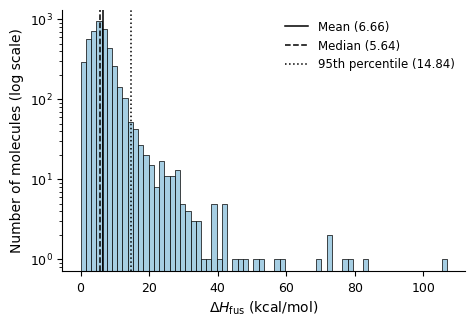

saved figures_colour\fig_main_01_dHfus_distribution.png


In [6]:
#MAIN 01: dHfus DISTRIBUTION OF THE CLEANED DATA SET 
y = clean["dHfus"]["y"].to_numpy(float)
fig, ax = plt.subplots(figsize=fs(5.2, 3.4))
ax.hist(y, bins=70, color=HISTFILL, edgecolor="black", linewidth=0.5)
ax.set_yscale("log")
for val, ls, lab in [(y.mean(), "-", f"Mean ({y.mean():.2f})"), (np.median(y), "--", f"Median ({np.median(y):.2f})"),
                     (np.quantile(y, 0.95), ":", f"95th percentile ({np.quantile(y, 0.95):.2f})")]:
    ax.axvline(val, color="black", ls=ls, lw=1.1, label=lab)
ax.set_xlabel(f"{SYM['dHfus']} ({UNIT['dHfus']})")
ax.set_ylabel("Number of molecules (log scale)")
ax.legend()
save(fig, "fig_main_01_dHfus_distribution")


In [7]:
# MEAN MW OF THE 39 FUSION ENTHALPY OUTLIERS, WITH AND WITHOUT THE FLUORINATED ETHER
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors

df = pd.read_csv("RAW DATA/dHfus_clean.csv")
smi_col = [c for c in df.columns if "smiles" in c.lower()][0]     # SMILES COLUMN
y_col = [c for c in df.columns if c != smi_col][0]                # FUSION ENTHALPY COLUMN (CHECK THIS IS THE RIGHT ONE)
print("COLUMNS USED:", smi_col, y_col)

thr = df[y_col].mean() + 4 * df[y_col].std()                      # 4 SD THRESHOLD (~30.1)
out = df[df[y_col] > thr].copy()
out["MW"] = out[smi_col].apply(lambda s: Descriptors.MolWt(Chem.MolFromSmiles(s)))

print("THRESHOLD:", round(thr, 2), "| N OUTLIERS:", len(out))
print("MEAN MW, ALL OUTLIERS:", round(out["MW"].mean(), 1))
print("MEDIAN MW, ALL OUTLIERS:", round(out["MW"].median(), 1))
ether = out["MW"].idxmin()                                        # FLUORINATED ETHER = LOWEST MW (460.5)
print("MW OF LOWEST-MW OUTLIER:", round(out.loc[ether, "MW"], 1))
print("MEAN MW, OTHER 38:", round(out.drop(ether)["MW"].mean(), 1))

COLUMNS USED: smiles dHfus [kcal/mol]
THRESHOLD: 30.07 | N OUTLIERS: 39
MEAN MW, ALL OUTLIERS: 924.8
MEDIAN MW, ALL OUTLIERS: 731.4
MW OF LOWEST-MW OUTLIER: 460.5
MEAN MW, OTHER 38: 937.0


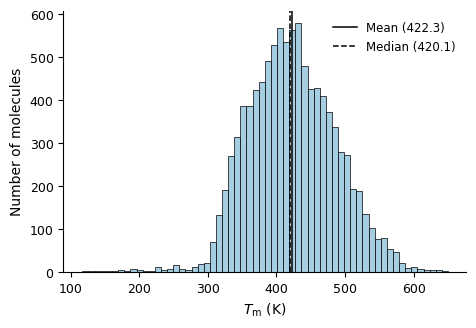

saved figures_colour\fig_main_02_Tm_distribution.png


In [8]:
#MAIN 02: Tm DISTRIBUTION OF THE CLEANED, SUBSAMPLED DATA SET
y = clean["Tm"]["y"].to_numpy(float)
fig, ax = plt.subplots(figsize=fs(5.2, 3.4))
ax.hist(y, bins=60, color=HISTFILL, edgecolor="black", linewidth=0.5)
for val, ls, lab in [(y.mean(), "-", f"Mean ({y.mean():.1f})"), (np.median(y), "--", f"Median ({np.median(y):.1f})")]:
    ax.axvline(val, color="black", ls=ls, lw=1.1, label=lab)
ax.set_xlabel(f"{SYM['Tm']} ({UNIT['Tm']})")
ax.set_ylabel("Number of molecules")
ax.legend()
save(fig, "fig_main_02_Tm_distribution")

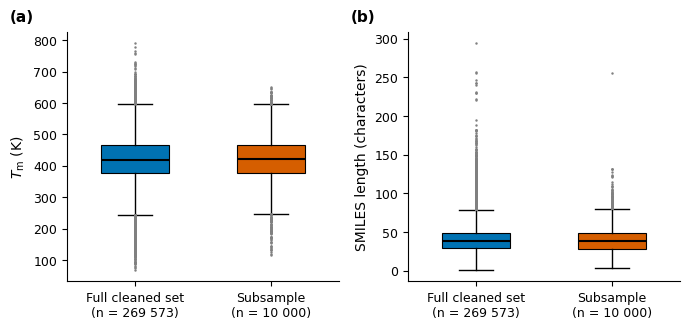

saved figures_colour\fig_main_03_Tm_subsample_check.png
Tm: mean 421.83 vs 422.26, median 419.1 vs 420.1, KS test p = 0.109
SMILES length: mean 39.80 vs 39.58, median 38.0 vs 38.0, KS test p = 0.319


In [9]:
#MAIN 03: Tm SUBSAMPLE CHECK, FULL CLEANED SET VS THE 10 000 SUBSAMPLE (NEEDS RAW DATA/Tm_clean_full.csv, THE CLEANED SET BEFORE SUBSAMPLING)
TM_FULL = Path("RAW DATA/Tm_clean_full.csv")
if TM_FULL.exists():
    full = pd.read_csv(TM_FULL)
    sub = clean["Tm"]
    full_tm, sub_tm = full[CLEAN["Tm"][1]].to_numpy(float), sub["y"].to_numpy(float)
    full_len, sub_len = full["smiles"].str.len().to_numpy(), sub["smiles"].str.len().to_numpy()
    fig, axes = plt.subplots(1, 2, figsize=fs(7.0, 3.4))
    for ax, (a, b), ylab, lab in zip(axes, [(full_tm, sub_tm), (full_len, sub_len)], [f"{SYM['Tm']} ({UNIT['Tm']})", "SMILES length (characters)"], "ab"):
        bp = ax.boxplot([a, b], patch_artist=True, widths=0.5, medianprops=dict(color="black", lw=1.5), flierprops=dict(marker=".", markersize=1.5, markerfacecolor="grey", markeredgecolor="grey"))
        for k, patch in enumerate(bp["boxes"]):
            patch.set(facecolor=FILLS[k], edgecolor="black", hatch=HATCHES[k], lw=0.8)
        ax.set_xticks([1, 2])
        ax.set_xticklabels([f"Full cleaned set\n(n = {len(a):,})".replace(",", " "), f"Subsample\n(n = {len(b):,})".replace(",", " ")])
        ax.set_ylabel(ylab)
        panel(ax, f"({lab})")
    plt.tight_layout()
    save(fig, "fig_main_03_Tm_subsample_check")
    for nm, (a, b) in {"Tm": (full_tm, sub_tm), "SMILES length": (full_len, sub_len)}.items():
        print(f"{nm}: mean {a.mean():.2f} vs {b.mean():.2f}, median {np.median(a):.1f} vs {np.median(b):.1f}, KS test p = {stats.ks_2samp(a, b).pvalue:.3f}")
else:
    print("SKIPPED: RAW DATA/Tm_clean_full.csv NOT FOUND. SAVE THE FULL CLEANED Tm SET (BEFORE SUBSAMPLING) UNDER THAT NAME TO MAKE THIS FIGURE. THE OLD plots_Tm_subsample_check.png IS THE FALLBACK")

In [10]:


# TM SUMMARY: FULL CLEANED SET VS 10 000 SUBSAMPLE
import pandas as pd
from scipy.stats import skew, ks_2samp
full = pd.read_csv("RAW DATA/Tm_clean_full.csv")["Tm[K]"]   # FULL CLEANED SET
sub = pd.read_csv("RAW DATA/Tm_clean.csv")["Tm[K]"]          # SUBSAMPLE
def summ(s):
    return {"count": len(s), "mean": s.mean(), "std": s.std(), "min": s.min(),
            "p5": s.quantile(.05), "median": s.median(), "p95": s.quantile(.95),
            "max": s.max(), "skew": skew(s)}                  # SAME STATS AS DHFUS TABLE
print(pd.DataFrame({"full": summ(full), "subsample": summ(sub)}).round(2))
print("KS FULL VS SUBSAMPLE:", ks_2samp(full, sub))          



             full  subsample
count   269573.00   10000.00
mean       421.83     422.26
std         64.03      64.33
min         68.15     116.15
p5         327.65     327.15
median     419.15     420.15
p95        530.15     530.15
max        790.15     649.82
skew         0.06      -0.02
KS FULL VS SUBSAMPLE: KstestResult(statistic=np.float64(0.012268590326182494), pvalue=np.float64(0.10884629407404056), statistic_location=np.float64(403.3), statistic_sign=np.int8(1))


### 5.3 Baseline results

dHfus: 5 of 450 points lie beyond the axis range (not shown)
Tm: 7 of 1000 points lie beyond the axis range (not shown)


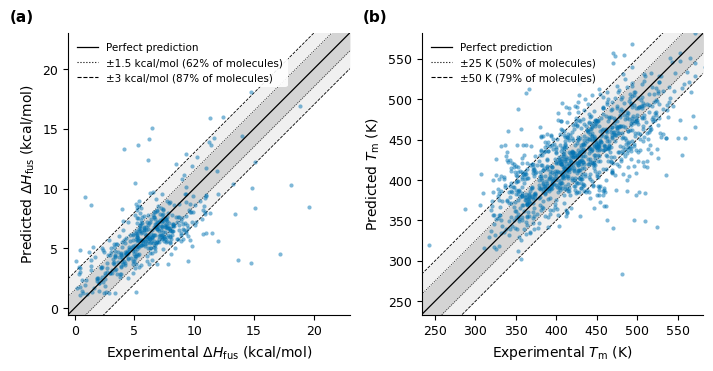

saved figures_colour\fig_main_04_baseline_parity.png


In [11]:
#MAIN 04: BASELINE PARITY PLOTS, SEED 0 (a = dHfus, b = Tm)
fig, axes = plt.subplots(1, 2, figsize=fs(7.2, 3.8))
for ax, ds, lab in zip(axes, DS, "ab"):
    n_out = parity(ax, pred[ds], ds)
    panel(ax, f"({lab})")
    print(f"{ds}: {n_out} of {len(pred[ds])} points lie beyond the axis range (not shown)")
plt.tight_layout()
save(fig, "fig_main_04_baseline_parity")

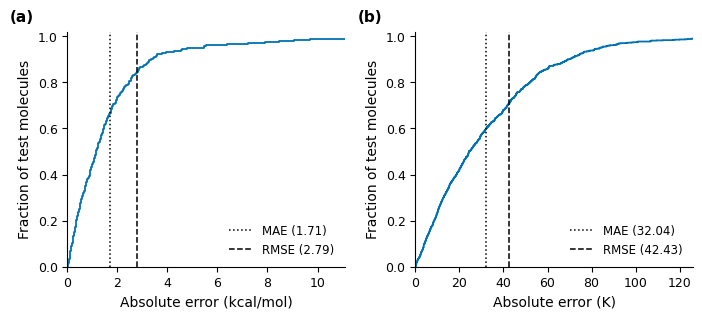

saved figures_colour\fig_main_05_baseline_cumulative_error.png


In [12]:
#MAIN 05: BASELINE CUMULATIVE ERROR DISTRIBUTION, SEED 0 (a = dHfus, b = Tm)
fig, axes = plt.subplots(1, 2, figsize=fs(7.2, 3.3))
for ax, ds, lab in zip(axes, DS, "ab"):
    e = np.sort(pred[ds]["abs_error"].to_numpy(float))
    mae, rmse = e.mean(), float(np.sqrt((e ** 2).mean()))
    ax.step(e, np.arange(1, len(e) + 1) / len(e), where="post", color=LN[0], lw=1.3)
    ax.axvline(mae, color="black", ls=":", lw=1.1, label=f"MAE ({mae:.2f})")
    ax.axvline(rmse, color="black", ls="--", lw=1.1, label=f"RMSE ({rmse:.2f})")
    ax.set_xlim(0, np.quantile(e, 0.99))
    ax.set_ylim(0, 1.02)
    ax.set_xlabel(f"Absolute error ({UNIT[ds]})")
    ax.set_ylabel("Fraction of test molecules")
    ax.legend(loc="lower right")
    panel(ax, f"({lab})")
plt.tight_layout()
save(fig, "fig_main_05_baseline_cumulative_error")

### 5.4 Joback comparison (in distribution)

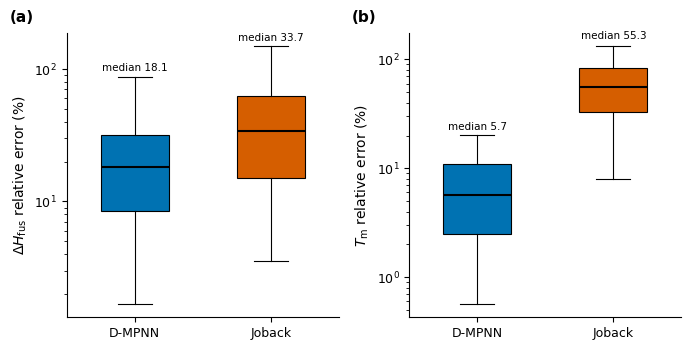

saved figures_colour\fig_main_06_joback_relative_error.png
dataset   n  model_median_rel  joback_median_rel  model_MAE  joback_MAE
  dHfus 401             18.06              33.72       1.67        2.85
     Tm 963              5.70              55.33      32.27      261.81
                       0       1
dataset            dHfus      Tm
n_test               450    1000
n_joback_valid       410     963
model_MAE           1.69   32.27
joback_MAE          2.82  261.81
MAE_diff            1.13  229.54
CI_low              0.84  219.04
CI_high             1.42  240.34
model_RMSE           2.8   42.79
joback_RMSE         4.13  309.25
pct_model_closer   65.61   94.81
model_median_rel   18.06     5.7
joback_median_rel  33.72   55.33
n_rel                401     963


In [13]:
#MAIN 06: RELATIVE ERROR OF THE MODEL VS JOBACK ON THE SAME SEED-0 TEST MOLECULES 
fig, axes = plt.subplots(1, 2, figsize=fs(7.0, 3.6))
summary = []
for ax, ds, lab in zip(axes, DS, "ab"):
    d = pred[ds]
    d = d[d["joback"].notna() & (d["y_true"].abs() > NEAR_ZERO[ds])]
    model_rel = 100 * d["abs_error"] / d["y_true"].abs()
    jo_rel = 100 * d["joback_abs"] / d["y_true"].abs()
    box_pair(ax, [model_rel.to_numpy(), jo_rel.to_numpy()], ["D-MPNN", "Joback"])
    ax.set_ylabel(f"{SYM[ds]} relative error (%)")
    panel(ax, f"({lab})")
    summary.append(dict(dataset=ds, n=len(d), model_median_rel=model_rel.median(), joback_median_rel=jo_rel.median(),
                        model_MAE=d["abs_error"].mean(), joback_MAE=d["joback_abs"].mean()))
plt.tight_layout()
save(fig, "fig_main_06_joback_relative_error")
print(pd.DataFrame(summary).round(2).to_string(index=False))
#IN-DISTRIBUTION JOBACK COMPARISON: NUMBERS FOR THE REPORT (SAME MOLECULES AS MAIN 06 PLUS A PAIRED BOOTSTRAP OF THE MAE DIFFERENCE)
rng_b = np.random.default_rng(0)                                                  #FIXED SEED SO THE INTERVALS ARE REPRODUCIBLE
rows = []
for ds in DS:
    d = pred[ds][pred[ds]["joback"].notna()].copy()                               #ONLY MOLECULES WITH A VALID JOBACK PREDICTION
    e_m, e_j = d["abs_error"].to_numpy(), d["joback_abs"].to_numpy()
    diff = e_j - e_m                                                              #POSITIVE = MODEL CLOSER THAN JOBACK
    idx = rng_b.integers(0, len(d), size=(10000, len(d)))                         #10 000 PAIRED RESAMPLES OF THE MOLECULES
    boot = diff[idx].mean(axis=1)
    rel_ok = d["y_true"].abs() > NEAR_ZERO[ds]
    rows.append(dict(dataset=ds, n_test=len(pred[ds]), n_joback_valid=len(d),
                     model_MAE=e_m.mean(), joback_MAE=e_j.mean(), MAE_diff=diff.mean(),
                     CI_low=np.percentile(boot, 2.5), CI_high=np.percentile(boot, 97.5),
                     model_RMSE=np.sqrt((e_m ** 2).mean()), joback_RMSE=np.sqrt((e_j ** 2).mean()),
                     pct_model_closer=100 * (e_m < e_j).mean(),
                     model_median_rel=(100 * e_m[rel_ok] / d["y_true"].abs()[rel_ok]).median(),
                     joback_median_rel=(100 * e_j[rel_ok] / d["y_true"].abs()[rel_ok]).median(),
                     n_rel=int(rel_ok.sum())))
print(pd.DataFrame(rows).round(2).T.to_string())

### 5.5 Sub-questions

dHfus: 23 molecules above 1049 g/mol are beyond the axis (not shown)
Tm: 50 molecules above 729 g/mol are beyond the axis (not shown)


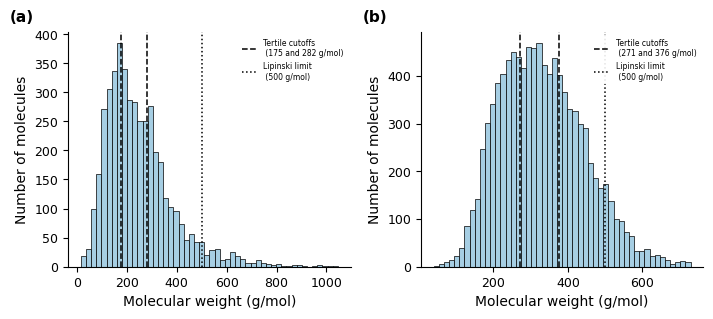

saved figures_colour\fig_main_07_MW_distribution.png


In [14]:
#MAIN 07: MOLECULAR WEIGHT DISTRIBUTION OF THE TRAINING DATA WITH THE TERTILE CUTOFFS USED FOR THE SMALL / LARGE SUBSETS (a = dHfus, b = Tm)
fig, axes = plt.subplots(1, 2, figsize=fs(7.2, 3.3))
for ax, ds, lab in zip(axes, DS, "ab"):
    m = clean[ds]["MW"].dropna().to_numpy()
    xmax = np.quantile(m, 0.995)
    ax.hist(m[m <= xmax], bins=50, color=HISTFILL, edgecolor="black", linewidth=0.5)
    cut = pd.read_csv(f"mw_subsets_cutoffs_{ds}.csv").set_index("cutoff")["MW"]
    ax.axvline(cut["small_max"], color="black", ls="--", lw=1.1, label=f"Tertile cutoffs\n ({cut['small_max']:.0f} and {cut['large_min']:.0f} g/mol)")
    ax.axvline(cut["large_min"], color="black", ls="--", lw=1.1)
    if xmax > 500:
        ax.axvline(500, color="black", ls=":", lw=1.1, label="Lipinski limit\n (500 g/mol)")
    ax.set_xlabel("Molecular weight (g/mol)")
    ax.set_ylabel("Number of molecules")
    ax.legend(loc="upper right", fontsize=5.5)
    panel(ax, f"({lab})")
    print(f"{ds}: {int((m > xmax).sum())} molecules above {xmax:.0f} g/mol are beyond the axis (not shown)")
plt.tight_layout()
save(fig, "fig_main_07_MW_distribution")

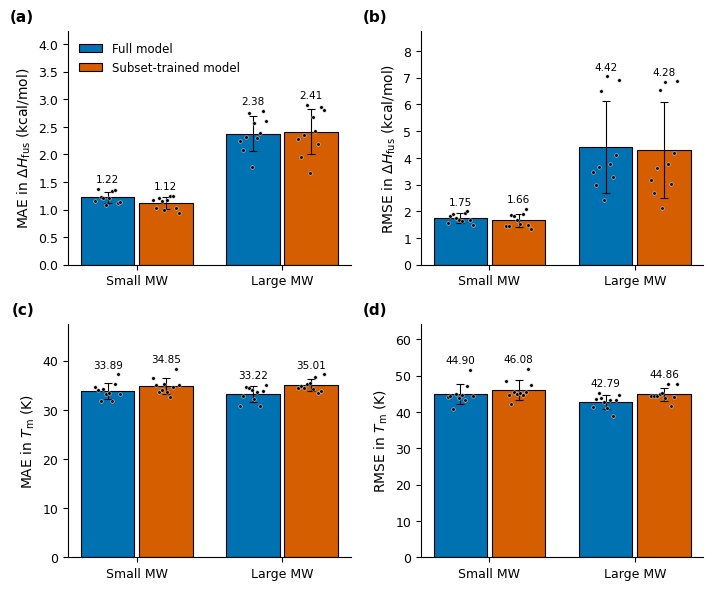

saved figures_colour\fig_main_08_MW_subsets.png
dataset   subset metric   full  subset_trained   diff  paired_p  seeds_subset_better
  dHfus small_MW    MAE  1.222           1.120 -0.102     0.012                    9
  dHfus large_MW    MAE  2.377           2.407  0.030     0.488                    3
  dHfus small_MW   RMSE  1.747           1.661 -0.086     0.077                    8
  dHfus large_MW   RMSE  4.419           4.281 -0.138     0.016                    8
     Tm small_MW    MAE 33.886          34.846  0.960     0.009                    2
     Tm large_MW    MAE 33.217          35.007  1.789     0.001                    1
     Tm small_MW   RMSE 44.903          46.082  1.179     0.048                    1
     Tm large_MW   RMSE 42.794          44.860  2.066     0.002                    1


In [15]:
#MAIN 08: FULL BASELINE MODEL VS MODEL TRAINED ON ONLY THE SMALL OR LARGE MW SUBSET, SAME TEST MOLECULES, 10 SEEDS (BARS = MEAN, ERROR BARS = STD, DOTS = SEEDS)
SUBS = ["small_MW", "large_MW"]
fig, axes = plt.subplots(2, 2, figsize=fs(7.2, 6.0))
tests = []
for i, ds in enumerate(DS):
    r = mw[ds]
    for j, mtr in enumerate(["mae", "rmse"]):
        ax = axes[i, j]
        keys = ["full", "sub"]
        means = [[r[r["subset"] == s].sort_values("seed")[f"{k}_{mtr}"].mean() for s in SUBS] for k in keys]
        stds = [[r[r["subset"] == s].sort_values("seed")[f"{k}_{mtr}"].std(ddof=1) for s in SUBS] for k in keys]
        dots = [[r[r["subset"] == s].sort_values("seed")[f"{k}_{mtr}"].to_numpy() for s in SUBS] for k in keys]
        grouped_bars(ax, ["Small MW", "Large MW"], ["Full model", "Subset-trained model"], means, stds, dots, legend=(i == 0 and j == 0))
        ax.set_ylabel(f"{mtr.upper()} in {SYM[ds]} ({UNIT[ds]})")
        panel(ax, f"({'abcd'[2 * i + j]})")
        for s in SUBS:
            q = r[r["subset"] == s].sort_values("seed")
            tests.append(dict(dataset=ds, subset=s, metric=mtr.upper(), full=q[f"full_{mtr}"].mean(), subset_trained=q[f"sub_{mtr}"].mean(),
                              diff=q[f"sub_{mtr}"].mean() - q[f"full_{mtr}"].mean(), paired_p=stats.ttest_rel(q[f"sub_{mtr}"], q[f"full_{mtr}"]).pvalue,
                              seeds_subset_better=int((q[f"sub_{mtr}"] < q[f"full_{mtr}"]).sum())))
plt.tight_layout()
save(fig, "fig_main_08_MW_subsets")
print(pd.DataFrame(tests).round(3).to_string(index=False))

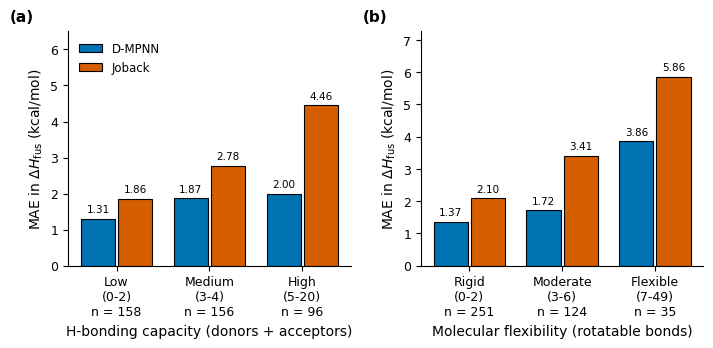

saved figures_colour\fig_main_09_dHfus_HB_flexibility.png
     bin        variable   n  model_MAE  joback_MAE
     Low        HB_total 158      1.309       1.857
  Medium        HB_total 156      1.875       2.775
    High        HB_total  96      2.000       4.455
   Rigid rotatable_bonds 251      1.365       2.097
Moderate rotatable_bonds 124      1.722       3.407
Flexible rotatable_bonds  35      3.859       5.863


In [16]:
#MAIN 09: dHfus ERROR BY HYDROGEN-BONDING CAPACITY (a) AND BY FLEXIBILITY (b), MODEL VS JOBACK ON THE SAME MOLECULES (SEED-0 TEST SET). SAME DEFINITIONS AS NOTEBOOK 04:
#HB_total = HBD + HBA (RDKit Lipinski), FLEXIBILITY = ROTATABLE BONDS, BINS = TERTILES OF THE SEED-0 TEST SET (WITH THE SAME FALLBACK EDGES IF TERTILE EDGES REPEAT)
d = pred["dHfus"].copy()
d["HB_total"] = d["smiles"].apply(lambda s: Lipinski.NumHDonors(Chem.MolFromSmiles(s)) + Lipinski.NumHAcceptors(Chem.MolFromSmiles(s)))
d["rotatable_bonds"] = d["smiles"].apply(lambda s: Descriptors.NumRotatableBonds(Chem.MolFromSmiles(s)))


def tertile_bin(v, labels, fallback):
    edges = v.quantile([0, 1 / 3, 2 / 3, 1]).unique()
    if len(edges) < 4:
        edges = fallback
    return pd.cut(v, bins=edges, labels=labels, include_lowest=True)


d["hb_bin"] = tertile_bin(d["HB_total"], ["Low", "Medium", "High"], [d["HB_total"].min() - 0.5, 1.5, 3.5, d["HB_total"].max() + 0.5])
d["rb_bin"] = tertile_bin(d["rotatable_bonds"], ["Rigid", "Moderate", "Flexible"], [d["rotatable_bonds"].min() - 0.5, 2.5, 6.5, d["rotatable_bonds"].max() + 0.5])
comp = d[d["joback"].notna()]                                                    #MATCHED: ONLY MOLECULES WITH A VALID JOBACK PREDICTION
fig, axes = plt.subplots(1, 2, figsize=fs(7.2, 3.6))
tabs = []
for ax, bcol, vcol, xl, lab in zip(axes, ["hb_bin", "rb_bin"], ["HB_total", "rotatable_bonds"], ["H-bonding capacity (donors + acceptors)", "Molecular flexibility (rotatable bonds)"], "ab"):
    g = comp.groupby(bcol, observed=True)
    model_mae, jo_mae, labels = [], [], []
    for name, q in g:
        model_mae.append(q["abs_error"].mean())
        jo_mae.append(q["joback_abs"].mean())
        rng = f"{q[vcol].min():.0f}" if q[vcol].min() == q[vcol].max() else f"{q[vcol].min():.0f}-{q[vcol].max():.0f}"
        labels.append(f"{name}\n({rng})\nn = {len(q)}")
        tabs.append(dict(bin=name, variable=vcol, n=len(q), model_MAE=q["abs_error"].mean(), joback_MAE=q["joback_abs"].mean()))
    grouped_bars(ax, labels, ["D-MPNN", "Joback"], [model_mae, jo_mae], style=[0, 1], legend=(bcol == "hb_bin"))
    ax.set_xlabel(xl)
    ax.set_ylabel(f"MAE in {SYM['dHfus']} ({UNIT['dHfus']})")
    panel(ax, f"({lab})")
plt.tight_layout()
save(fig, "fig_main_09_dHfus_HB_flexibility")
print(pd.DataFrame(tabs).round(3).to_string(index=False))

### 5.6 Multitask

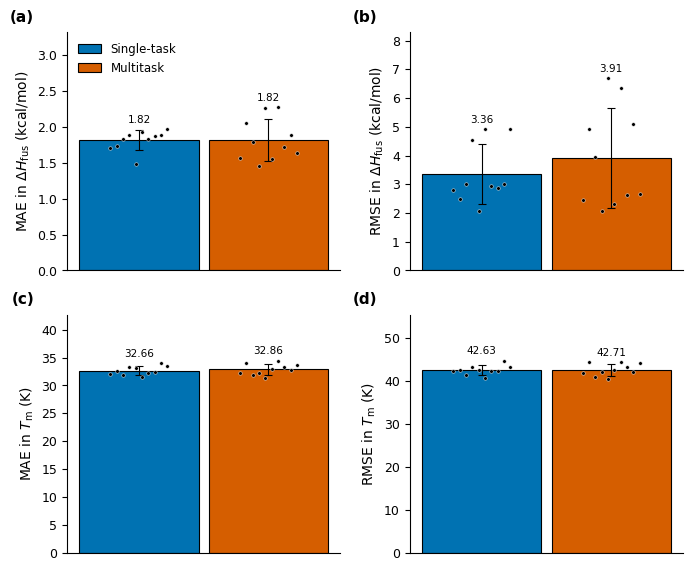

saved figures_colour\fig_main_10_multitask.png
dataset metric  single  multitask  welch_p
  dHfus    MAE   1.816      1.819    0.978
  dHfus   RMSE   3.359      3.909    0.407
     Tm    MAE  32.665     32.864    0.625
     Tm   RMSE  42.633     42.715    0.886


In [17]:
#MAIN 10: SINGLE-TASK BASELINE VS MULTITASK MODEL (POOLED DATA), 10 SEEDS (BARS = MEAN, ERROR BARS = STD, DOTS = SEEDS). TEST SETS DIFFER, SO THIS IS NOT PAIRED
fig, axes = plt.subplots(2, 2, figsize=fs(7.0, 5.8))
rows = []
for i, ds in enumerate(DS):
    for j, mtr in enumerate(["mae", "rmse"]):
        ax = axes[i, j]
        single = seeds[ds][find_col(seeds[ds], mtr)].to_numpy(float)
        multi = mt[mt["task"] == ds].sort_values("seed")[mtr].to_numpy(float)
        grouped_bars(ax, [""], ["Single-task", "Multitask"], [[single.mean()], [multi.mean()]], [[single.std(ddof=1)], [multi.std(ddof=1)]],
                     [[single], [multi]], legend=(i == 0 and j == 0))
        ax.set_ylabel(f"{mtr.upper()} in {SYM[ds]} ({UNIT[ds]})")
        ax.tick_params(axis="x", length=0)
        panel(ax, f"({'abcd'[2 * i + j]})")
        rows.append(dict(dataset=ds, metric=mtr.upper(), single=single.mean(), multitask=multi.mean(), welch_p=stats.ttest_ind(single, multi, equal_var=False).pvalue))
plt.tight_layout()
save(fig, "fig_main_10_multitask")
print(pd.DataFrame(rows).round(3).to_string(index=False))

### 5.7 Hybrid (Joback pretraining)

MAE hybrid - baseline: -0.02 | paired p = 0.388 | hybrid better in 6 of 10 seeds
RMSE hybrid - baseline: -0.011 | paired p = 0.693 | hybrid better in 5 of 10 seeds


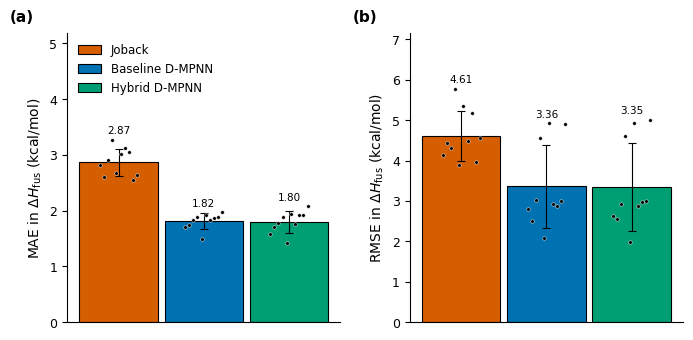

saved figures_colour\fig_main_11_hybrid.png


In [18]:
#MAIN 11: dHfus HYBRID MODEL (JOBACK PRETRAINING + FINE-TUNING) VS BASELINE VS JOBACK, SAME TEST SETS, 10 SEEDS
fig, axes = plt.subplots(1, 2, figsize=fs(7.0, 3.5))
for ax, mtr, lab in zip(axes, ["mae", "rmse"], "ab"):
    cols = [f"joback_{mtr}", f"baseline_{mtr}", f"hybrid_{mtr}"]
    grouped_bars(ax, [""], ["Joback", "Baseline D-MPNN", "Hybrid D-MPNN"], [[hy[c].mean()] for c in cols], [[hy[c].std(ddof=1)] for c in cols],
                 [[hy[c].to_numpy()] for c in cols], style=[1, 0, 2], legend=(mtr == "mae"))
    ax.set_ylabel(f"{mtr.upper()} in {SYM['dHfus']} ({UNIT['dHfus']})")
    ax.tick_params(axis="x", length=0)
    panel(ax, f"({lab})")
    print(mtr.upper(), "hybrid - baseline:", round((hy[f"hybrid_{mtr}"] - hy[f"baseline_{mtr}"]).mean(), 3),
          "| paired p =", round(stats.ttest_rel(hy[f"hybrid_{mtr}"], hy[f"baseline_{mtr}"]).pvalue, 3), "| hybrid better in", int((hy[f"hybrid_{mtr}"] < hy[f"baseline_{mtr}"]).sum()), "of", len(hy), "seeds")
plt.tight_layout()
save(fig, "fig_main_11_hybrid")

### 5.8 Out-of-distribution (Wyttenbach drugs)

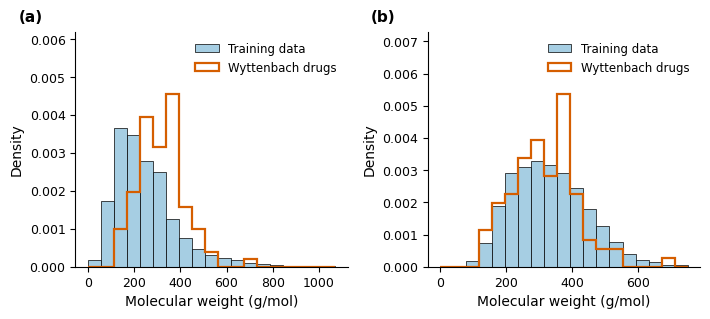

saved figures_colour\fig_main_12_OOD_MW_vs_training.png


In [19]:
#MAIN 12: MOLECULAR WEIGHT OF THE TRAINING DATA VS THE 90 WYTTENBACH DRUGS (NORMALISED, a = dHfus TRAINING SET, b = Tm TRAINING SET)
fig, axes = plt.subplots(1, 2, figsize=fs(7.2, 3.3))
for ax, ds, lab in zip(axes, DS, "ab"):
    tr, wy = clean[ds]["MW"].dropna().to_numpy(), ood_pred[ds]["MW"].dropna().to_numpy()
    xmax = np.quantile(tr, 0.995)
    edges = np.linspace(0, xmax+20, 20)
    ax.hist(tr, bins=edges, density=True, color=HISTFILL, edgecolor="black", linewidth=0.5, label="Training data")
    ax.hist(wy, bins=edges, density=True, histtype="step", edgecolor=LN[1], linewidth=1.6, label="Wyttenbach drugs")
    ax.set_xlabel("Molecular weight (g/mol)")
    ax.set_ylabel("Density")
    ax.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none", framealpha=0.9)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.3)
    panel(ax, f"({lab})")
plt.tight_layout()
save(fig, "fig_main_12_OOD_MW_vs_training")

dHfus: 0 of 90 points lie beyond the axis range (not shown)
Tm: 0 of 90 points lie beyond the axis range (not shown)


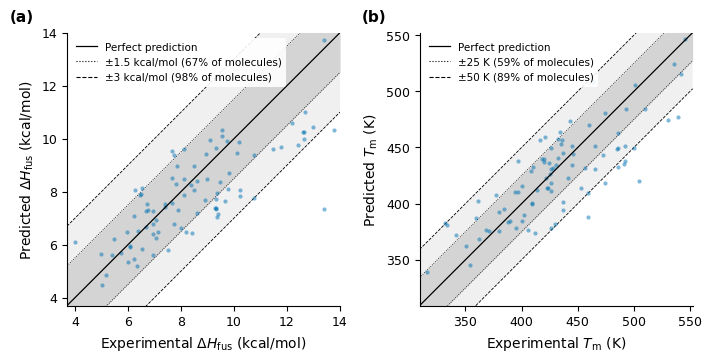

saved figures_colour\fig_main_13_OOD_parity.png

dHfus: five largest errors (kcal/mol)
    compound  y_true  y_pred  abs_error
   tamoxifen   13.38    7.36       6.03
itraconazole   13.77   10.32       3.44
    warfarin   10.76    7.78       2.98
 terfenadine   12.40    9.74       2.66
bicalutamide   12.64   10.01       2.64

Tm: five largest errors (K)
      compound  y_true  y_pred  abs_error
mefenamic acid   504.5  420.30      84.20
    bucindolol   459.0  388.19      70.81
    metolazone   539.0  476.80      62.20
  griseofulvin   491.2  434.81      56.39
    budesonide   530.0  474.08      55.92


In [20]:
#MAIN 13: OOD PARITY PLOTS ON THE WYTTENBACH DRUGS, SEED 0 (a = dHfus, b = Tm), SAME BANDS AS THE BASELINE PARITY PLOTS
fig, axes = plt.subplots(1, 2, figsize=fs(7.2, 3.8))
for ax, ds, lab in zip(axes, DS, "ab"):
    n_out = parity(ax, ood_pred[ds], ds)
    panel(ax, f"({lab})")
    print(f"{ds}: {n_out} of {len(ood_pred[ds])} points lie beyond the axis range (not shown)")
plt.tight_layout()
save(fig, "fig_main_13_OOD_parity")

#THE FIVE DRUGS WITH THE LARGEST ERROR, WITH NAMES
w = pd.read_csv("RAW DATA/wyttenbach_market_drugs.csv").dropna(subset=["smiles"])


def canon_nostereo(s):
    m = Chem.MolFromSmiles(s)
    if m is None:
        return None
    Chem.RemoveStereochemistry(m)
    return Chem.MolToSmiles(m)


names = dict(zip(w["smiles"].apply(canon_nostereo), w["compound"]))
for ds in DS:
    d = ood_pred[ds].copy()
    d["compound"] = d["smiles"].map(names)
    print(f"\n{ds}: five largest errors ({UNIT[ds]})")
    print(d.sort_values("abs_error", ascending=False).head(5)[["compound", "y_true", "y_pred", "abs_error"]].round(2).to_string(index=False))

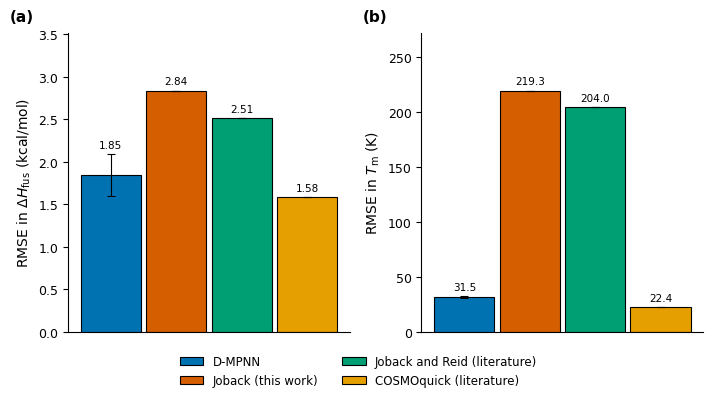

saved figures_colour\fig_main_14_OOD_method_comparison.png


In [21]:
#MAIN 14: OOD RMSE, THIS MODEL VS JOBACK (OWN AND LITERATURE) VS COSMOquick (LITERATURE VALUES). ERROR BAR = STD OVER 10 SEEDS (ONLY THE D-MPNN HAS ONE)
def short(m):
    if "Baseline" in m:
        return "D-MPNN"
    if "own" in m:
        return "Joback (this work)"
    if "Joback" in m:
        return "Joback and Reid (literature)"
    return "COSMOquick (literature)"


fig, axes = plt.subplots(1, 2, figsize=fs(7.2, 3.6))
for ax, ds, lab in zip(axes, DS, "ab"):
    t = ood_summary[ood_summary["Property"] == ds].reset_index(drop=True)
    means = [[v] for v in t["RMSE"]]
    stds = [[v] for v in t["RMSE_std"].fillna(0)]
    grouped_bars(ax, [""], [short(m) for m in t["Method"]], means, stds, style=list(range(len(t))),
                 fmt="{:.2f}" if ds == "dHfus" else "{:.1f}", legend=False)
    ax.set_ylabel(f"RMSE in {SYM[ds]} ({UNIT[ds]})")
    ax.tick_params(axis="x", length=0)
    panel(ax, f"({lab})")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.12))        #ONE LEGEND UNDER BOTH PANELS
plt.tight_layout()
save(fig, "fig_main_14_OOD_method_comparison")

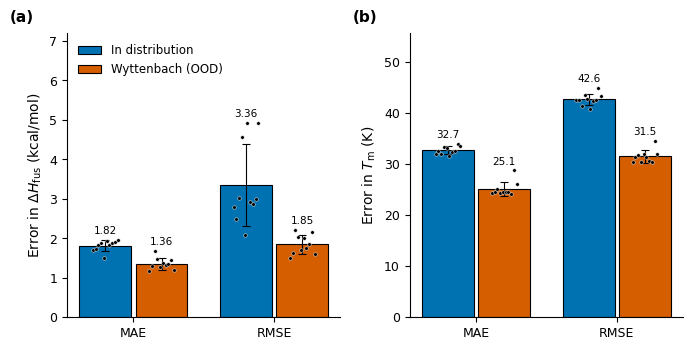

saved figures_colour\fig_main_15_ID_vs_OOD.png


In [22]:
#MAIN 15: IN-DISTRIBUTION (SCAFFOLD TEST SETS) VS OUT-OF-DISTRIBUTION (WYTTENBACH) ERROR OF THE SAME 10 MODELS (BARS = MEAN, ERROR BARS = STD, DOTS = SEEDS)
fig, axes = plt.subplots(1, 2, figsize=fs(7.0, 3.6))
for ax, ds, lab in zip(axes, DS, "ab"):
    idv = [seeds[ds][find_col(seeds[ds], m)].to_numpy(float) for m in ["mae", "rmse"]]
    oodv = [ood_seeds[ds][f"ood_{m}"].to_numpy(float) for m in ["mae", "rmse"]]
    grouped_bars(ax, ["MAE", "RMSE"], ["In distribution", "Wyttenbach (OOD)"], [[v.mean() for v in idv], [v.mean() for v in oodv]],
                 [[v.std(ddof=1) for v in idv], [v.std(ddof=1) for v in oodv]], [idv, oodv], legend=(ds == "dHfus"),
                 fmt="{:.2f}" if ds == "dHfus" else "{:.1f}")
    ax.set_ylabel(f"Error in {SYM[ds]} ({UNIT[ds]})")
    panel(ax, f"({lab})")
plt.tight_layout()
save(fig, "fig_main_15_ID_vs_OOD")


In [23]:
#HOW DIFFERENT IS THE WYTTENBACH SET FROM THE TRAINING DATA? (MW STATISTICS, KS TEST, NEAREST-NEIGHBOUR STRUCTURAL SIMILARITY)
from rdkit import DataStructs
from rdkit.Chem import rdFingerprintGenerator

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)               #MORGAN FINGERPRINTS (RADIUS 2, 2048 BITS)


def fingerprints(smiles):
    return [gen.GetFingerprint(Chem.MolFromSmiles(s)) for s in smiles]


def nn_similarity(query_smiles, ref_smiles):
    #FOR EACH QUERY MOLECULE: THE HIGHEST TANIMOTO SIMILARITY TO ANY MOLECULE IN THE REFERENCE SET
    ref_fps = fingerprints(ref_smiles)
    return np.array([max(DataStructs.BulkTanimotoSimilarity(fp, ref_fps)) for fp in fingerprints(query_smiles)])


mw_rows, nn_rows = [], []
for ds in DS:
    tr = clean[ds]["MW"].dropna().to_numpy()
    wy = ood_pred[ds]["MW"].dropna().to_numpy()
    p5, p95 = np.quantile(tr, [0.05, 0.95])
    ks = stats.ks_2samp(tr, wy)
    mw_rows.append(dict(dataset=ds, n_train=len(tr), n_wyttenbach=len(wy),
                        train_mean=tr.mean(), wyttenbach_mean=wy.mean(), train_median=np.median(tr), wyttenbach_median=np.median(wy),
                        train_IQR=f"{np.quantile(tr, .25):.0f}-{np.quantile(tr, .75):.0f}", wyttenbach_IQR=f"{np.quantile(wy, .25):.0f}-{np.quantile(wy, .75):.0f}",
                        wyttenbach_in_train_5_95_pct=100 * ((wy >= p5) & (wy <= p95)).mean(), wyttenbach_in_train_range_pct=100 * ((wy >= tr.min()) & (wy <= tr.max())).mean(),
                        KS_statistic=ks.statistic, KS_p=ks.pvalue))
    #STRUCTURAL SIMILARITY: WYTTENBACH DRUGS VS THE TRAINING SET, AND (FOR COMPARISON) THE SEED-0 SCAFFOLD TEST MOLECULES VS THE REST OF THE DATA SET
    sim_ood = nn_similarity(ood_pred[ds]["smiles"], clean[ds]["smiles"])
    canon = lambda x: Chem.MolToSmiles(Chem.MolFromSmiles(x))                          #CANONICAL SMILES SO A TEST MOLECULE IS NEVER COMPARED WITH ITSELF
    test_set = {canon(x) for x in pred[ds]["smiles"]}
    rest = [x for x in clean[ds]["smiles"] if canon(x) not in test_set]
    sim_id = nn_similarity(pred[ds]["smiles"], rest)
    for name, v in [("Wyttenbach drugs", sim_ood), ("Seed-0 scaffold test set", sim_id)]:
        nn_rows.append(dict(dataset=ds, query=name, n=len(v), median_NN_similarity=np.median(v), IQR=f"{np.quantile(v, .25):.2f}-{np.quantile(v, .75):.2f}",
                            pct_below_0_5=100 * (v < 0.5).mean(), pct_above_0_8=100 * (v >= 0.8).mean()))
    print(f"{ds}: Mann-Whitney on NN similarity (drugs vs scaffold test), p = {stats.mannwhitneyu(sim_ood, sim_id).pvalue:.3g}")
print(pd.DataFrame(mw_rows).round(2).T.to_string())
print(pd.DataFrame(nn_rows).round(2).to_string(index=False))


[09:27:43] WARNING: not removing hydrogen atom without neighbors
[09:27:43] WARNING: not removing hydrogen atom without neighbors
[09:27:43] WARNING: not removing hydrogen atom without neighbors
[09:27:43] WARNING: not removing hydrogen atom without neighbors
[09:27:43] WARNING: not removing hydrogen atom without neighbors
[09:27:43] WARNING: not removing hydrogen atom without neighbors
[09:27:43] WARNING: not removing hydrogen atom without neighbors
[09:27:43] Unusual charge on atom 6 number of radical electrons set to zero
[09:27:44] WARNING: not removing hydrogen atom without neighbors
[09:27:44] WARNING: not removing hydrogen atom without neighbors
[09:27:44] WARNING: not removing hydrogen atom without neighbors
[09:27:44] WARNING: not removing hydrogen atom without neighbors
[09:27:44] WARNING: not removing hydrogen atom without neighbors
[09:27:44] WARNING: not removing hydrogen atom without neighbors
[09:27:44] WARNING: not removing hydrogen atom without neighbors
[09:27:45] Unu

dHfus: Mann-Whitney on NN similarity (drugs vs scaffold test), p = 0.417
Tm: Mann-Whitney on NN similarity (drugs vs scaffold test), p = 1.85e-11
                                     0        1
dataset                          dHfus       Tm
n_train                           4501    10000
n_wyttenbach                        90       90
train_mean                      255.25   333.84
wyttenbach_mean                 318.31   318.31
train_median                    222.46   322.39
wyttenbach_median               314.32   314.32
train_IQR                      153-311  245-409
wyttenbach_IQR                 251-371  251-371
wyttenbach_in_train_5_95_pct     98.89    93.33
wyttenbach_in_train_range_pct    100.0    100.0
KS_statistic                      0.36     0.13
KS_p                               0.0     0.07
dataset                    query    n  median_NN_similarity       IQR  pct_below_0_5  pct_above_0_8
  dHfus         Wyttenbach drugs   90                  0.53 0.38-0.65          48.

In [24]:
#REFERENCE: ERROR OF A MODEL THAT ALWAYS PREDICTS THE TYPICAL (MEDIAN) VALUE OF THE DATA SET, VS THE D-MPNN AND JOBACK. THE MEDIAN IS TAKEN FROM THE FULL CLEAN SET (A SLIGHT SIMPLIFICATION, THE TEST MOLECULES ARE INCLUDED)
rows = []
for ds in DS:
    med = clean[ds]["y"].median()
    for name, d in [("Seed-0 scaffold test set", pred[ds]), ("Wyttenbach drugs", ood_pred[ds])]:
        y, yhat = d["y_true"].to_numpy(float), d["y_pred"].to_numpy(float)
        mae_model = np.abs(yhat - y).mean()
        mae_median = np.abs(med - y).mean()
        r2 = 1 - ((yhat - y) ** 2).sum() / ((y - y.mean()) ** 2).sum()
        rows.append(dict(dataset=ds, test_set=name, n=len(y), MAE_model=mae_model, MAE_always_predict_median=mae_median,
                         error_reduction_pct=100 * (1 - mae_model / mae_median), R2=r2))
print(pd.DataFrame(rows).round(2).to_string(index=False))

dataset                 test_set    n  MAE_model  MAE_always_predict_median  error_reduction_pct   R2
  dHfus Seed-0 scaffold test set  450       1.71                       2.50                31.60 0.44
  dHfus         Wyttenbach drugs   90       1.16                       2.90                60.00 0.53
     Tm Seed-0 scaffold test set 1000      32.04                      47.78                32.95 0.47
     Tm         Wyttenbach drugs   90      24.24                      38.88                37.67 0.62


## APPENDIX

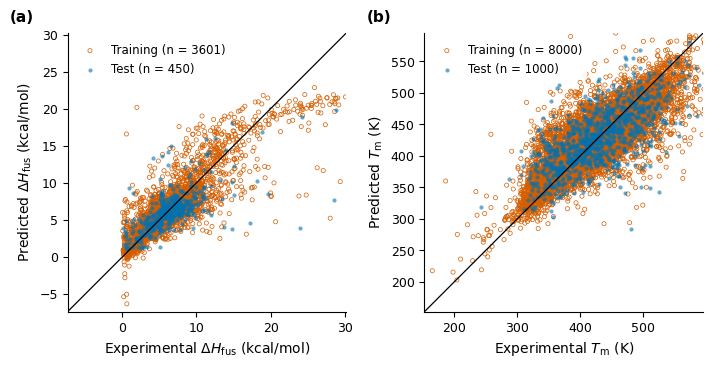

saved figures_colour\fig_app_02_train_vs_test_parity.png


In [25]:
#APPENDIX 02: TRAINING VS TEST PARITY (SEED 0), CHECKS FOR OVERFITTING (a = dHfus, b = Tm)
fig, axes = plt.subplots(1, 2, figsize=fs(7.2, 3.6))
for ax, ds, lab in zip(axes, DS, "ab"):
    files = sorted(glob.glob(f"{ds}_baseline*train*pred*.csv"))
    if not files:
        print(f"{ds}: NO TRAIN PREDICTION FILE FOUND")
        continue
    tr, te = pd.read_csv(files[0]), pred[ds]
    both = np.concatenate([tr["y_true"], tr["y_pred"], te["y_true"], te["y_pred"]])
    lo, hi = both.min(), np.quantile(both, CLIP_Q)
    pad = 0.03 * (hi - lo)
    lo, hi = lo - pad, hi + pad
    ax.scatter(tr["y_true"], tr["y_pred"], s=9 * S, facecolors="none", edgecolors=(JC if COLOUR else MID), linewidths=0.5, label=f"Training (n = {len(tr)})")
    ax.scatter(te["y_true"], te["y_pred"], s=9 * S, color=SC, alpha=0.6, linewidths=0, label=f"Test (n = {len(te)})")
    ax.plot([lo, hi], [lo, hi], color="black", lw=0.9)
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect("equal")
    ax.set_xlabel(f"Experimental {SYM[ds]} ({UNIT[ds]})")
    ax.set_ylabel(f"Predicted {SYM[ds]} ({UNIT[ds]})")
    ax.legend(loc="upper left")
    panel(ax, f"({lab})")
plt.tight_layout()
save(fig, "fig_app_02_train_vs_test_parity")

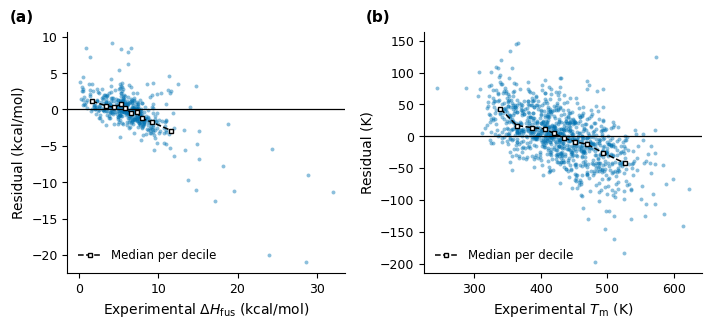

saved figures_colour\fig_app_03_residuals.png


In [26]:
#APPENDIX 03: RESIDUALS (PREDICTED - EXPERIMENTAL) VS EXPERIMENTAL VALUE, SEED 0. DASHED LINE WITH SQUARES = MEDIAN RESIDUAL PER DECILE OF THE TRUE VALUE (a = dHfus, b = Tm)
fig, axes = plt.subplots(1, 2, figsize=fs(7.2, 3.4))
for ax, ds, lab in zip(axes, DS, "ab"):
    d = pred[ds]
    ax.scatter(d["y_true"], d["resid"], s=8 * S, color=SC, alpha=0.45, linewidths=0)
    ax.axhline(0, color="black", lw=0.9)
    grp = d.groupby(pd.qcut(d["y_true"], 10, duplicates="drop"))
    ax.plot(grp["y_true"].median(), grp["resid"].median(), color="black", ls="--", lw=1.1, marker="s", markersize=3.5, markerfacecolor="white", label="Median per decile")
    ax.set_xlabel(f"Experimental {SYM[ds]} ({UNIT[ds]})")
    ax.set_ylabel(f"Residual ({UNIT[ds]})")
    ax.legend(loc="lower left")
    panel(ax, f"({lab})")
plt.tight_layout()
save(fig, "fig_app_03_residuals")

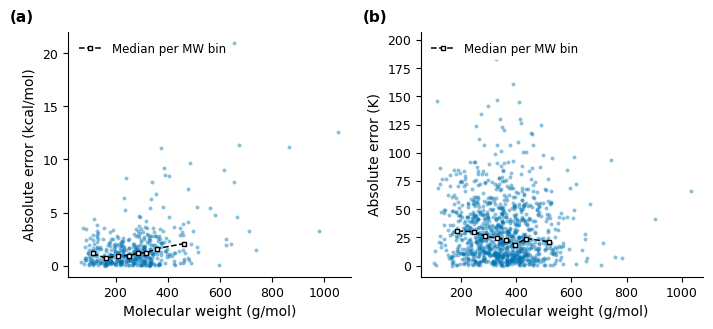

saved figures_colour\fig_app_04_error_vs_MW.png


In [27]:
#APPENDIX 04: ABSOLUTE ERROR VS MOLECULAR WEIGHT, SEED 0. DASHED LINE WITH SQUARES = MEDIAN ERROR PER MW QUANTILE BIN (a = dHfus, b = Tm)
fig, axes = plt.subplots(1, 2, figsize=fs(7.2, 3.4))
for ax, ds, lab in zip(axes, DS, "ab"):
    d = pred[ds].dropna(subset=["MW"])
    ax.scatter(d["MW"], d["abs_error"], s=8 * S, color=SC, alpha=0.45, linewidths=0)
    grp = d.groupby(pd.qcut(d["MW"], 8, duplicates="drop"))
    ax.plot(grp["MW"].median(), grp["abs_error"].median(), color="black", ls="--", lw=1.1, marker="s", markersize=3.5, markerfacecolor="white", label="Median per MW bin")
    ax.set_xlabel("Molecular weight (g/mol)")
    ax.set_ylabel(f"Absolute error ({UNIT[ds]})")
    ax.legend(loc="upper left")
    panel(ax, f"({lab})")
plt.tight_layout()
save(fig, "fig_app_04_error_vs_MW")

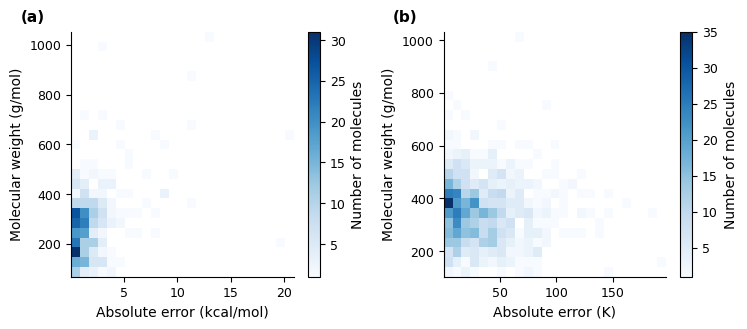

saved figures_colour\fig_app_05_error_MW_2Dhist.png


In [28]:
#APPENDIX 05: JOINT DISTRIBUTION OF ABSOLUTE ERROR AND MOLECULAR WEIGHT, SEED 0 (DARKER = MORE MOLECULES, EMPTY CELLS WHITE) (a = dHfus, b = Tm)
fig, axes = plt.subplots(1, 2, figsize=fs(7.6, 3.4))
for ax, ds, lab in zip(axes, DS, "ab"):
    d = pred[ds].dropna(subset=["MW"])
    h = ax.hist2d(d["abs_error"], d["MW"], bins=[25, 25], cmap=CMAP, cmin=1)
    cb = plt.colorbar(h[3], ax=ax)
    cb.set_label("Number of molecules")
    ax.set_xlabel(f"Absolute error ({UNIT[ds]})")
    ax.set_ylabel("Molecular weight (g/mol)")
    panel(ax, f"({lab})")
plt.tight_layout()
save(fig, "fig_app_05_error_MW_2Dhist")

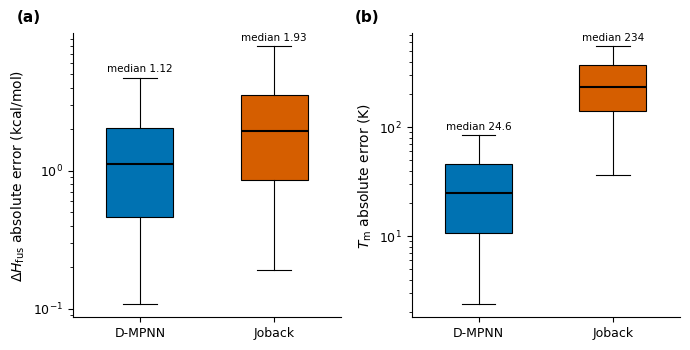

saved figures_colour\fig_app_06_joback_absolute_error.png


In [29]:
#APPENDIX 06: ABSOLUTE ERROR OF THE MODEL VS JOBACK ON THE SAME SEED-0 TEST MOLECULES 
fig, axes = plt.subplots(1, 2, figsize=fs(7.0, 3.6))
for ax, ds, lab in zip(axes, DS, "ab"):
    d = pred[ds][pred[ds]["joback"].notna()]
    box_pair(ax, [d["abs_error"].to_numpy(), d["joback_abs"].to_numpy()], ["D-MPNN", "Joback"])
    ax.set_ylabel(f"{SYM[ds]} absolute error ({UNIT[ds]})")
    panel(ax, f"({lab})")
plt.tight_layout()
save(fig, "fig_app_06_joback_absolute_error")

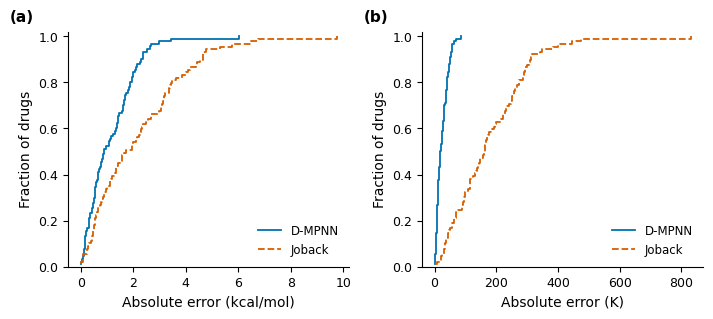

saved figures_colour\fig_app_07_OOD_cumulative_error.png


In [30]:
#APPENDIX 07: OOD CUMULATIVE ERROR DISTRIBUTION, MODEL (SEED 0) VS JOBACK (a = dHfus, b = Tm)
fig, axes = plt.subplots(1, 2, figsize=fs(7.2, 3.3))
for ax, ds, lab in zip(axes, DS, "ab"):
    for e, ls, name, cl in [(ood_pred[ds]["abs_error"], "-", "D-MPNN", LN[0]), (ood_jo[ds]["joback_abs_error"], "--", "Joback", LN[1])]:
        e = np.sort(e.dropna().to_numpy(float))
        ax.step(e, np.arange(1, len(e) + 1) / len(e), where="post", color=cl, ls=ls, lw=1.3, label=name)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel(f"Absolute error ({UNIT[ds]})")
    ax.set_ylabel("Fraction of drugs")
    ax.legend(loc="lower right")
    panel(ax, f"({lab})")
plt.tight_layout()
save(fig, "fig_app_07_OOD_cumulative_error")

dHfus: 2 of 313 points lie beyond the axis range (not shown)
Tm: 6 of 1133 points lie beyond the axis range (not shown)


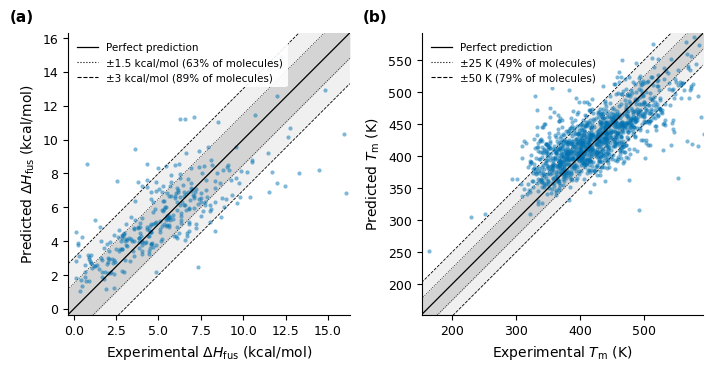

saved figures_colour\fig_app_08_multitask_parity.png


In [31]:
#APPENDIX 08: MULTITASK MODEL PARITY PLOTS, POOLED DATA, SEED 0 (a = dHfus, b = Tm)
fig, axes = plt.subplots(1, 2, figsize=fs(7.2, 3.8))
for ax, ds, lab in zip(axes, DS, "ab"):
    f = Path(f"multitask_pooled_{ds}_predictions.csv")
    if not f.exists():
        print("MISSING", f)
        continue
    d = pd.read_csv(f).dropna(subset=["y_true", "y_pred"])
    n_out = parity(ax, d, ds)
    panel(ax, f"({lab})")
    print(f"{ds}: {n_out} of {len(d)} points lie beyond the axis range (not shown)")
plt.tight_layout()
save(fig, "fig_app_08_multitask_parity")

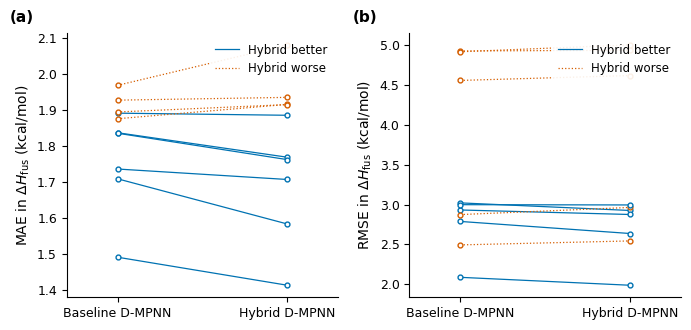

saved figures_colour\fig_app_09_hybrid_paired_seeds.png


In [32]:
#APPENDIX 09: HYBRID VS BASELINE FOR EACH SEED (LINES JOIN THE SAME SEED, SAME SPLIT) (a = MAE, b = RMSE)
fig, axes = plt.subplots(1, 2, figsize=fs(7.0, 3.4))
for ax, mtr, lab in zip(axes, ["mae", "rmse"], "ab"):
    for _, row in hy.iterrows():
        better = row[f"hybrid_{mtr}"] < row[f"baseline_{mtr}"]
        ax.plot([0, 1], [row[f"baseline_{mtr}"], row[f"hybrid_{mtr}"]], color=LN[0] if better else LN[1], ls="-" if better else ":", lw=0.9, marker="o", markersize=3.5, markerfacecolor="white")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Baseline D-MPNN", "Hybrid D-MPNN"])
    ax.set_xlim(-0.3, 1.3)
    ax.set_ylabel(f"{mtr.upper()} in {SYM['dHfus']} ({UNIT['dHfus']})")
    ax.legend(handles=[Line2D([0], [0], color=LN[0], ls="-", lw=0.9, label="Hybrid better"), Line2D([0], [0], color=LN[1], ls=":", lw=0.9, label="Hybrid worse")], loc="upper right")
    panel(ax, f"({lab})")
plt.tight_layout()
save(fig, "fig_app_09_hybrid_paired_seeds")

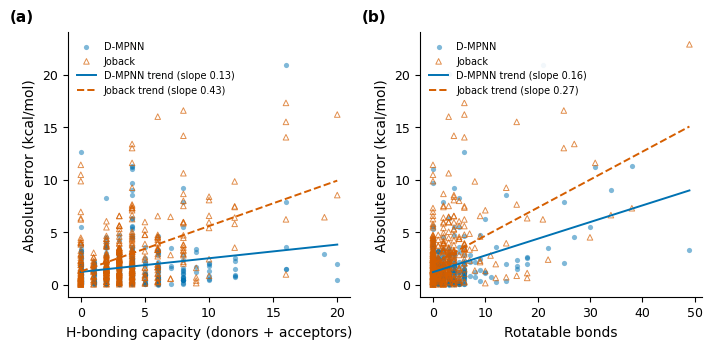

saved figures_colour\fig_app_10_error_vs_HB_flexibility_with_joback.png


In [33]:
#APPENDIX 10: ABSOLUTE ERROR VS H-BONDING CAPACITY (a) AND VS ROTATABLE BONDS (b), MODEL (FILLED CIRCLES, SOLID TREND) VS JOBACK (OPEN TRIANGLES, DASHED TREND), SEED 0
fig, axes = plt.subplots(1, 2, figsize=fs(7.2, 3.6))
for ax, vcol, xl, lab in zip(axes, ["HB_total", "rotatable_bonds"], ["H-bonding capacity (donors + acceptors)", "Rotatable bonds"], "ab"):
    ax.scatter(comp[vcol], comp["abs_error"], s=14 * S, color=SC, alpha=0.5, marker="o", linewidths=0, label="D-MPNN")
    ax.scatter(comp[vcol], comp["joback_abs"], s=16 * S, facecolors="none", edgecolors=JC, alpha=0.7, marker="^", linewidths=0.7, label="Joback")
    xs = np.array([comp[vcol].min(), comp[vcol].max()])
    for col, cl, ls, nm in [("abs_error", LN[0], "-", "D-MPNN"), ("joback_abs", LN[1], "--", "Joback")]:
        sl, ic = np.polyfit(comp[vcol], comp[col], 1)
        ax.plot(xs, sl * xs + ic, color=cl, ls=ls, lw=1.4, label=f"{nm} trend (slope {sl:.2f})")
    ax.set_xlabel(xl)
    ax.set_ylabel(f"Absolute error ({UNIT['dHfus']})")
    ax.legend(loc="upper left", fontsize=7 * S)
    panel(ax, f"({lab})")
plt.tight_layout()
save(fig, "fig_app_10_error_vs_HB_flexibility_with_joback")

In [34]:
#LIST OF EVERYTHING SAVED, IN ORDER
for p in sorted(FIG_DIR.glob("fig_*.png")):
    print(p.name)
    

fig_app_01_loss_curves.png
fig_app_02_train_vs_test_parity.png
fig_app_03_residuals.png
fig_app_04_error_vs_MW.png
fig_app_05_error_MW_2Dhist.png
fig_app_06_joback_absolute_error.png
fig_app_07_OOD_cumulative_error.png
fig_app_08_multitask_parity.png
fig_app_09_hybrid_paired_seeds.png
fig_app_10_error_vs_HB_flexibility_with_joback.png
fig_main_01_dHfus_distribution.png
fig_main_02_Tm_distribution.png
fig_main_03_Tm_subsample_check.png
fig_main_04_baseline_parity.png
fig_main_05_baseline_cumulative_error.png
fig_main_06_joback_relative_error.png
fig_main_07_MW_distribution.png
fig_main_08_MW_subsets.png
fig_main_09_dHfus_HB_flexibility.png
fig_main_10_multitask.png
fig_main_11_hybrid.png
fig_main_12_OOD_MW_vs_training.png
fig_main_13_OOD_parity.png
fig_main_14_OOD_method_comparison.png
fig_main_15_ID_vs_OOD.png


In [35]:
#JOBACK COVERAGE: HOW MANY MOLECULES GET A VALID JOBACK PREDICTION, AND HOW MANY OF THE MULTI-COMPONENT ONES
import thermo                                                                                  #FOR THE LIBRARY VERSION
from chemprop_utils import joback_predict_dHfus, joback_predict_Tm
fn = {"dHfus": joback_predict_dHfus, "Tm": joback_predict_Tm}
for ds in DS:
    for name, d in [("Seed-0 test set", pred[ds]), ("Wyttenbach drugs", ood_pred[ds])]:
        v = d["smiles"].apply(fn[ds])
        ok = v.notna()
        multi = d["smiles"].str.contains(r"\.")                                                #MULTI-COMPONENT SMILES CONTAIN A DOT
        print(f"{ds} | {name}: JOBACK VALID {int(ok.sum())} / {len(d)} | MULTI-COMPONENT: {int(multi.sum())}, OF WHICH VALID: {int((ok & multi).sum())}")
print("thermo version:", thermo.__version__)


dHfus | Seed-0 test set: JOBACK VALID 410 / 450 | MULTI-COMPONENT: 53, OF WHICH VALID: 50
dHfus | Wyttenbach drugs: JOBACK VALID 89 / 90 | MULTI-COMPONENT: 0, OF WHICH VALID: 0
Tm | Seed-0 test set: JOBACK VALID 963 / 1000 | MULTI-COMPONENT: 4, OF WHICH VALID: 4
Tm | Wyttenbach drugs: JOBACK VALID 89 / 90 | MULTI-COMPONENT: 0, OF WHICH VALID: 0
thermo version: 0.6.1


In [36]:
   d = pred["dHfus"].copy()
   d["mw_bin"] = pd.qcut(d["MW"], 3, labels=["Small", "Medium", "Large"])
   v = d.dropna(subset=["joback_abs"])
   print(v.groupby("mw_bin", observed=True).agg(n=("abs_error", "size"),
         model_mae=("abs_error", "mean"), joback_mae=("joback_abs", "mean")).round(2))

          n  model_mae  joback_mae
mw_bin                            
Small   140       1.14        1.34
Medium  132       1.48        2.49
Large   138       2.43        4.63
